In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from mol_faith.notebooks.results_analysis.shared import get_target_colors, load_raw_data, get_model_colors

In [ ]:

benzene_target_base_path = '../../../results/benzene_target'
benzene_raw_data_df = load_raw_data(base_dir=benzene_target_base_path, target_name='benzene')

conjugated_system_target_base_path = '../../../results/conjugated_system_target'
conjugated_system_raw_data_df = load_raw_data(base_dir=conjugated_system_target_base_path, target_name='conjugated_system')

hbond_donor_target_base_path = '../../../results/hbond_donor'
hbond_donor_raw_data_df = load_raw_data(base_dir=hbond_donor_target_base_path, target_name='hbond_donor')

Auto-discovered thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Loading thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer @ threshold 0.1: 6900 rows
  gnn_explainer @ threshold 0.2: 6900 rows
  gnn_explainer @ threshold 0.3: 6900 rows
  gnn_explainer @ threshold 0.4: 6900 rows
  gnn_explainer @ threshold 0.5: 6900 rows
  gnn_explainer @ threshold 0.6: 6900 rows
  gnn_explainer @ threshold 0.7: 6900 rows
  gnn_explainer @ threshold 0.8: 6900 rows
  gnn_explainer @ threshold 0.9: 6900 rows
  gnn_explainer total: 62100 rows across 9 thresholds
  grad_cam @ threshold 0.1: 6900 rows
  grad_cam @ threshold 0.2: 6900 rows
  grad_cam @ threshold 0.3: 6900 rows
  grad_cam @ threshold 0.4: 6900 rows
  grad_cam @ threshold 

In [ ]:
def plot_fidelity_by_threshold(dataframes, figsize=(10, 6), save_path=None):
    merged_df = pd.concat(dataframes, ignore_index=True)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    target_names = merged_df['target_name'].unique()

    model_colors = get_target_colors()

    label_mapping = {
        'benzene': 'Benzene',
        'conjugated_system': 'Conjugated System',
        'hbond_donor': 'Hbond Donor'
    }

    for target_name in target_names:
        target_df = merged_df[merged_df['target_name'] == target_name]
        
        medians = target_df.groupby('threshold')['fid_plus'].median().reset_index()
        
        ax.plot(medians['threshold'], medians['fid_plus'], 
                marker='o', markersize=7, linewidth=2,
                label=target_name, color=model_colors[label_mapping[target_name]])
    


    handles, labels = ax.get_legend_handles_labels()
    new_labels = [label_mapping.get(label, label) for label in labels]
    ax.legend(handles, new_labels)

    ax.set_xlabel('Threshold', fontsize=7)
    ax.set_ylabel('Median Fid+', fontsize=7)
    ax.tick_params(axis='both', labelsize=7)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, format='pdf', dpi=300, bbox_inches='tight')
    
    plt.show()
    return fig, ax

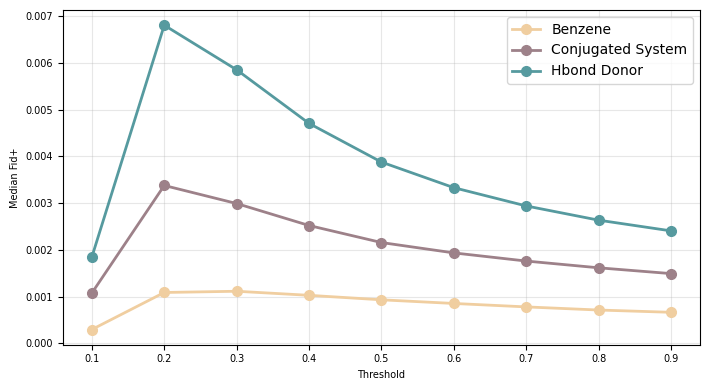

In [ ]:
dataframes = [benzene_raw_data_df, 
              conjugated_system_raw_data_df, 
              hbond_donor_raw_data_df]

fig, ax = plot_fidelity_by_threshold(dataframes, figsize=(7.2, 4), save_path='./fid_by_threshold_analysis.pdf')

In [ ]:
def plot_fidelity_by_threshold_per_target(dataframes, figsize=(12, 8), save_path=None):
    merged_df = pd.concat(dataframes, ignore_index=True)
    
    target_names = merged_df['target_name'].unique()
    n_targets = len(target_names)
    
    model_colors = get_model_colors()  # expected to map model names to colors

    label_mapping = {
        'benzene': 'Benzene',
        'conjugated_system': 'Conjugated System',
        'hbond_donor': 'Hbond Donor'
    }

    fig, axes = plt.subplots(1, n_targets, figsize=figsize, sharey=True)
    if n_targets == 1:
        axes = [axes]

    for ax, target_name in zip(axes, target_names):
        target_df = merged_df[merged_df['target_name'] == target_name]

        for model_name, model_df in target_df.groupby('model'):
            medians = model_df.groupby('threshold')['fid_plus'].median().reset_index()
            color = model_colors.get(model_name, None)
            ax.plot(
                medians['threshold'], medians['fid_plus'],
                marker='o', markersize=5, linewidth=2,
                label=model_name, color=color
            )

        ax.set_title(label_mapping.get(target_name, target_name), fontsize=10)
        ax.set_xlabel('Threshold', fontsize=8)
        ax.tick_params(axis='both', labelsize=8)
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel('Median Fid+', fontsize=8)

    handles, labels = axes[-1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=min(4, len(labels)), fontsize=8, frameon=False)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    if save_path:
        plt.savefig(save_path, format='pdf', dpi=300, bbox_inches='tight')

    plt.show()
    
    return fig, axes

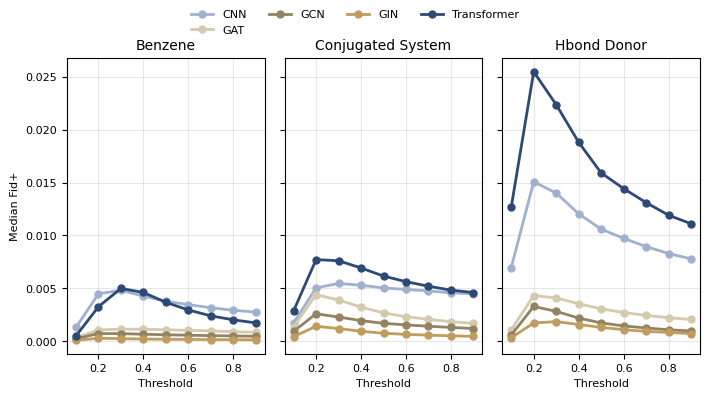

In [ ]:
dataframes = [benzene_raw_data_df, 
              conjugated_system_raw_data_df, 
              hbond_donor_raw_data_df]

fig, ax = plot_fidelity_by_threshold_per_target(dataframes, figsize=(7.2, 4), save_path='./fid_by_threshold_analysis_per_target.pdf')